## Thực nghiệm 5: Thử tham số learning_rate cho XGBoost
Thực nghiệm XGBoost trên tập A gồm 3.539 mẫu và 36 đặc trưng, giảm tham số learning_rate từ 0.1 xuống 0.05 để kiểm tra khả năng cải thiện mô hình. Hai cấu hình được đánh giá bằng Stratified 5-fold CV với shuffle=True, random_state=42 và chỉ số chính là CV Macro-F1. Các tham số còn lại và quy trình tiền xử lý được giữ nguyên. Kết quả được lưu dưới dạng Excel, CSV và biểu đồ trong thư mục thực nghiệm.

# 1. Cấu hình và tham số

In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
import sklearn
from IPython.display import display
from xgboost import XGBClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

# Tìm thư mục gốc của dự án
cwd = Path.cwd().resolve()
project_dir = next(
    (p for p in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
     if (p / "data" / "processed" / "development.csv").is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục dự án có data/processed/development.csv. "
        "Hãy mở đúng thư mục ML01_Student_Dropout rồi chạy lại notebook."
    )

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = project_dir / "experiments" / "2026-11-14_ThuThamSo_XGB_Khoi"
N_FOLDS = 5
SEED = 42

# Chỉ thay đổi learning_rate: 0.1 -> 0.05
# Giữ nguyên n_estimators=150, max_depth=3 và các tham số còn lại.
configs = {
    "XGBoost goc (learning_rate=0.1)": {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.1},
    "XGBoost thu (learning_rate=0.05)": {"n_estimators": 150, "max_depth": 3, "learning_rate": 0.05},
}

print("Project:", project_dir)
print("Output:", output_dir)
print("XGBoost:", __import__("xgboost").__version__)
print("sklearn:", sklearn.__version__)
display(pd.DataFrame([{"Cau hinh": name, **params} for name, params in configs.items()]))

Project: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout
Output: C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_XGB_Khoi
XGBoost: 3.4.1
sklearn: 1.9.1


,Cau hinh,n_estimators,max_depth,learning_rate
0,XGBoost goc (learning_rate=0.1),150,3,0.10
1,XGBoost thu (learning_rate=0.05),150,3,0.05


# 2. Huấn luyện và đánh giá hai cấu hình XGBoost

In [2]:
# Đọc tập development, không sử dụng test.csv
data = pd.read_csv(data_path)
data.columns = [" ".join(c.split()) for c in data.columns]
assert not data.columns.duplicated().any()
assert data.isna().sum().sum() == 0, "Phát hiện missing: cần kiểm tra dữ liệu."

X = data.drop(columns="Target")
label_names = ["Dropout", "Enrolled", "Graduate"]
label_mapping = {label: i for i, label in enumerate(label_names)}
assert set(data["Target"].unique()) == set(label_names)
y = data["Target"].map(label_mapping).astype(int)

categorical_cols = [
    "Marital status", "Application mode", "Course",
    "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]
binary_cols = [
    "Daytime/evening attendance", "Displaced",
    "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender",
    "Scholarship holder", "International"
]
numeric_cols = [
    "Application order", "Previous qualification (grade)",
    "Admission grade", "Age at enrollment",
    "Unemployment rate", "Inflation rate", "GDP"
] + [
    f"Curricular units {semester} sem ({measure})"
    for semester in ["1st", "2nd"]
    for measure in ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]
]
assigned = categorical_cols + binary_cols + numeric_cols
assert len(assigned) == len(set(assigned)) == 36
assert set(assigned) == set(X.columns)
for col in binary_cols:
    assert set(X[col].unique()) <= {0, 1}, col

def build_pipeline(params):
    # Tiền xử lý giống notebook XGBoost gốc; fit riêng trong từng fold.
    processor = ColumnTransformer([
        ("category", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("numeric", "passthrough", numeric_cols),
        ("binary", "passthrough", binary_cols),
    ])
    model = XGBClassifier(
        **params,
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )
    return Pipeline([("preprocessing", processor), ("model", model)])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X, y))
scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
    "recall_dropout": make_scorer(
        recall_score, labels=[0], average="macro", zero_division=0
    ),
}

summary_rows = []
fold_tables = []
for name, params in configs.items():
    print(f"Đang đánh giá: {name}")
    started = time.perf_counter()
    scores = cross_validate(
        build_pipeline(params), X, y,
        cv=folds, scoring=scoring,
        return_train_score=True, n_jobs=1, error_score="raise"
    )
    elapsed = time.perf_counter() - started

    fold_scores = pd.DataFrame({
        "fold": range(1, N_FOLDS + 1),
        "model": name,
        "train_macro_f1": scores["train_macro_f1"],
        "test_macro_f1": scores["test_macro_f1"],
        "test_accuracy": scores["test_accuracy"],
        "test_weighted_f1": scores["test_weighted_f1"],
        "test_recall_dropout": scores["test_recall_dropout"],
        "fit_time": scores["fit_time"],
        "score_time": scores["score_time"],
    })
    fold_tables.append(fold_scores)
    summary_rows.append({
        "model": name,
        "n_estimators": params["n_estimators"],
        "max_depth": params["max_depth"],
        "learning_rate": params["learning_rate"],
        "cv_macro_f1": scores["test_macro_f1"].mean(),
        "cv_macro_f1_std": scores["test_macro_f1"].std(ddof=1),
        "cv_accuracy": scores["test_accuracy"].mean(),
        "cv_weighted_f1": scores["test_weighted_f1"].mean(),
        "cv_recall_dropout": scores["test_recall_dropout"].mean(),
        "train_macro_f1": scores["train_macro_f1"].mean(),
        "mean_fit_seconds": scores["fit_time"].mean(),
        "total_seconds": elapsed,
    })

results = pd.DataFrame(summary_rows)
fold_results = pd.concat(fold_tables, ignore_index=True)
old_score = results.loc[results["learning_rate"].eq(0.1), "cv_macro_f1"].iloc[0]
new_score = results.loc[results["learning_rate"].eq(0.05), "cv_macro_f1"].iloc[0]
delta = new_score - old_score

print(f"\nlearning_rate=0.1 : {old_score:.6f}")
print(f"learning_rate=0.05: {new_score:.6f}")
print(f"Chênh lệch (mới - cũ): {delta:+.6f}")
if delta > 0:
    print("Nhận xét: Trong lần đánh giá này, learning_rate=0.05 có CV Macro-F1 cao hơn.")
elif delta < 0:
    print("Nhận xét: Trong lần đánh giá này, learning_rate=0.1 có CV Macro-F1 cao hơn.")
else:
    print("Nhận xét: Hai cấu hình có cùng CV Macro-F1.")

display(results.round(6))
display(fold_results.round(6))

Đang đánh giá: XGBoost goc (learning_rate=0.1)
Đang đánh giá: XGBoost thu (learning_rate=0.05)

learning_rate=0.1 : 0.706293
learning_rate=0.05: 0.691357
Chênh lệch (mới - cũ): -0.014936
Nhận xét: Trong lần đánh giá này, learning_rate=0.1 có CV Macro-F1 cao hơn.


,model,n_estimators,max_depth,learning_rate,cv_macro_f1,cv_macro_f1_std,cv_accuracy,cv_weighted_f1,cv_recall_dropout,train_macro_f1,mean_fit_seconds,total_seconds
0,XGBoost goc (learning_rate=0.1),150,3,0.10,0.706293,0.015629,0.780447,0.768198,0.765994,0.804711,0.614505,3.590338
1,XGBoost thu (learning_rate=0.05),150,3,0.05,0.691357,0.017372,0.771971,0.757170,0.750189,0.751644,0.741211,4.355497


,fold,model,train_macro_f1,test_macro_f1,test_accuracy,test_weighted_f1,test_recall_dropout,fit_time,score_time
0,1,XGBoost goc (learning_rate=0.1),0.801055,0.701472,0.772599,0.762096,0.731278,0.607493,0.067518
1,2,XGBoost goc (learning_rate=0.1),0.804504,0.692021,0.776836,0.759434,0.766520,0.756478,0.037161
2,3,XGBoost goc (learning_rate=0.1),0.799788,0.725989,0.798023,0.786282,0.820175,0.626417,0.027694
3,4,XGBoost goc (learning_rate=0.1),0.810476,0.692537,0.771186,0.756462,0.776316,0.534173,0.029908
4,5,XGBoost goc (learning_rate=0.1),0.807734,0.719446,0.783593,0.776717,0.735683,0.547964,0.030725
5,1,XGBoost thu (learning_rate=0.05),0.743591,0.692522,0.768362,0.756394,0.731278,0.595609,0.063259
6,2,XGBoost thu (learning_rate=0.05),0.752140,0.665806,0.762712,0.740793,0.748899,0.741924,0.036558
7,3,XGBoost thu (learning_rate=0.05),0.746577,0.710015,0.785311,0.772262,0.780702,0.693288,0.050919
8,4,XGBoost thu (learning_rate=0.05),0.756611,0.684517,0.765537,0.749265,0.754386,0.855626,0.043381
9,5,XGBoost thu (learning_rate=0.05),0.759302,0.703926,0.777935,0.767136,0.735683,0.819607,0.050044


# 3. Tổng hợp và xuất kết quả thực nghiệm

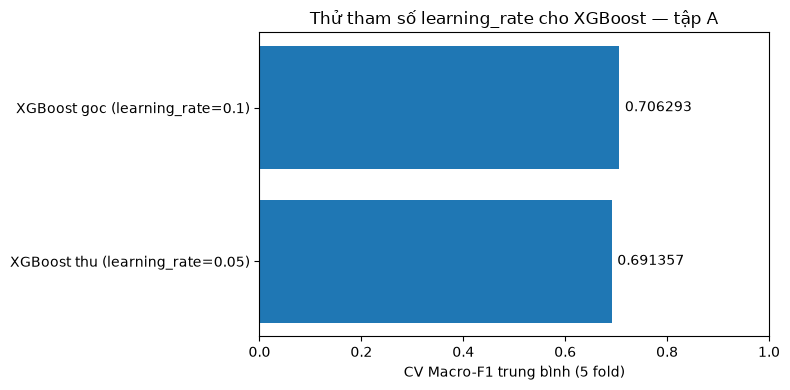


Đã xuất các file:
 - C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_XGB_Khoi\ket_qua.xlsx
 - C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_XGB_Khoi\ket_qua_tong_hop.csv
 - C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_XGB_Khoi\diem_tung_fold.csv
 - C:\Users\DELL\Desktop\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_XGB_Khoi\so_sanh_macro_f1.png


In [4]:
output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
summary_csv = output_dir / "ket_qua_tong_hop.csv"
fold_csv = output_dir / "diem_tung_fold.csv"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Nguoi thuc hien": "Nguyễn Hoàng Khởi",
    "Ngay thuc nghiem": "14/11/2026",
    "Du lieu": "data/processed/development.csv",
    "Tap dac trung": "A",
    "So mau": len(y),
    "So dac trung": X.shape[1],
    "So fold": N_FOLDS,
    "CV": "StratifiedKFold(shuffle=True, random_state=42)",
    "Chi so chinh": "CV Macro-F1 trung binh",
    "Tham so thay doi": "learning_rate: 0.1 -> 0.05",
    "sklearn_version": sklearn.__version__,
}])

config_table = pd.DataFrame([
    {"Cau hinh": name, **params} for name, params in configs.items()
])
results.to_csv(summary_csv, index=False, encoding="utf-8-sig")
fold_results.to_csv(fold_csv, index=False, encoding="utf-8-sig")
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    run_info.to_excel(writer, sheet_name="Thong tin thuc nghiem", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"])
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình (5 fold)")
ax.set_title("Thử tham số learning_rate cho XGBoost — tập A")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()
plt.close(fig)

print("\nĐã xuất các file:")
for path in [excel_path, summary_csv, fold_csv, image_path]:
    print(" -", path)

# 4. Nhận xét
Sau khi chạy thực nghiệm, đối chiếu CV Macro-F1 trung bình của hai cấu hình learning_rate=0.1 và learning_rate=0.05.
- Nếu CV Macro-F1 của learning_rate=0.05 cao hơn, cấu hình giảm learning rate cho kết quả tốt hơn trong lần thực nghiệm này.
- Nếu CV Macro-F1 của learning_rate=0.05 thấp hơn, cấu hình ban đầu learning_rate=0.1 vẫn cho kết quả tốt hơn.
- Ghi nhận thêm độ lệch chuẩn CV Macro-F1 để xem mức độ ổn định giữa 5 fold.
Lưu ý: Chỉ thay đổi learning_rate; n_estimators=150, max_depth=3, các tham số còn lại, tiền xử lý và cách chia fold được giữ nguyên. Chưa sử dụng test.csv để đánh giá.